# Detección de matrículas por contornos

Detector tradicional de matrículas, sin uso de aprendizaje profundo, únicamente utilizando detección de contornos. El código de esta detección se encuentra en [`common/contours.py`](../common/contours.py) y [`common/contour_selection.py`](../common/contour_selection.py). En este cuaderno se detalla el _pipeline_ de esta detección (`preprocesado` → `candidatos` → `filtros` → `puntuación de cada candidato` → `elección de candidato`).

## Índice

1. [Preparación](#1-preparación)
2. [Preprocesado](#2-preprocesado)
3. [Candidatos](#3-candidatos)
4. [Filtros](#4-filtros)
5. [Puntuación](#5-puntuación)
    - [Perfiles de brillo](#perfiles-de-brillo)
6. [Ejemplos](#6-ejemplos)

## 1. Preparación

In [1]:
import json
import math
import random
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, "..")
from common.contour_selection import candidate_interior, character_rows, find_valleys, profile
from common.contours import edge_mask, hough_line_mask, white_region_mask
from common.det_metrics import iou
from common.detectors import ContourPlateDetector
from common.paths import PLATES_DATA

SPLIT = PLATES_DATA / "val"

Lectura de las imágenes de validación y sus anotaciones. Las _bounding boxes_ YOLO de las anotaciones se pasan a píxeles `[x, y, w, h]`, el mismo formato que usan `iou` y los candidatos, reescaladas a la resolución de entrada del detector (`scale`):

In [2]:
def read_image(name):
    return cv2.imread(str(SPLIT / "images" / name))


def read_plates(name):
    return json.load(open(SPLIT / "annotations" / f"{Path(name).stem}.json", encoding="utf-8"))


def true_boxes(name, shape, scale=1.0):
    height, width = shape[:2]
    return [[scale * (cx - w / 2) * width, scale * (cy - h / 2) * height, scale * w * width, scale * h * height]
            for cx, cy, w, h in (p["rectangle"] for p in read_plates(name))]

Funciones auxiliares para dibujar los ejemplos de este cuaderno:
- **Verde**: matrícula anotada
- **Rojo**: candidatos de bordes
- **Azul**: candidatos de píxeles blancos
- **Naranja**: candidatos de HoughP
- **Amarillo**: candidatos que pasan el filtrado
- **Magenta**: candidato de mayor puntuación

In [3]:
GREEN, RED, BLUE, YELLOW, MAGENTA, ORANGE = (0, 200, 0), (0, 0, 255), (255, 128, 0), (0, 220, 255), (255, 0, 255), (0, 140, 255)
SOURCE_COLORS = {"edges": RED, "white": BLUE, "hough": ORANGE}


def draw_boxes(img, boxes, color, thickness=2):
    out = img.copy()
    for x, y, w, h in boxes:
        cv2.rectangle(out, (round(x), round(y)), (round(x + w), round(y + h)), color, thickness)
    return out


def draw_candidates(img, candidates, color, thickness=1):
    out = img.copy()
    cv2.polylines(out, [c.corners.round().astype(np.int32) for c in candidates], True, color, thickness)
    return out


def show_images(images, cols=4, size=3.5):
    rows = math.ceil(len(images) / cols)
    _, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (title, img) in zip(axes.flat, images.items()):
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if img.ndim == 3 else img, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title, fontsize=9)
    plt.tight_layout()
    plt.show()

Ejemplo de imágenes recortadas, con la matrícula anotada en verde:

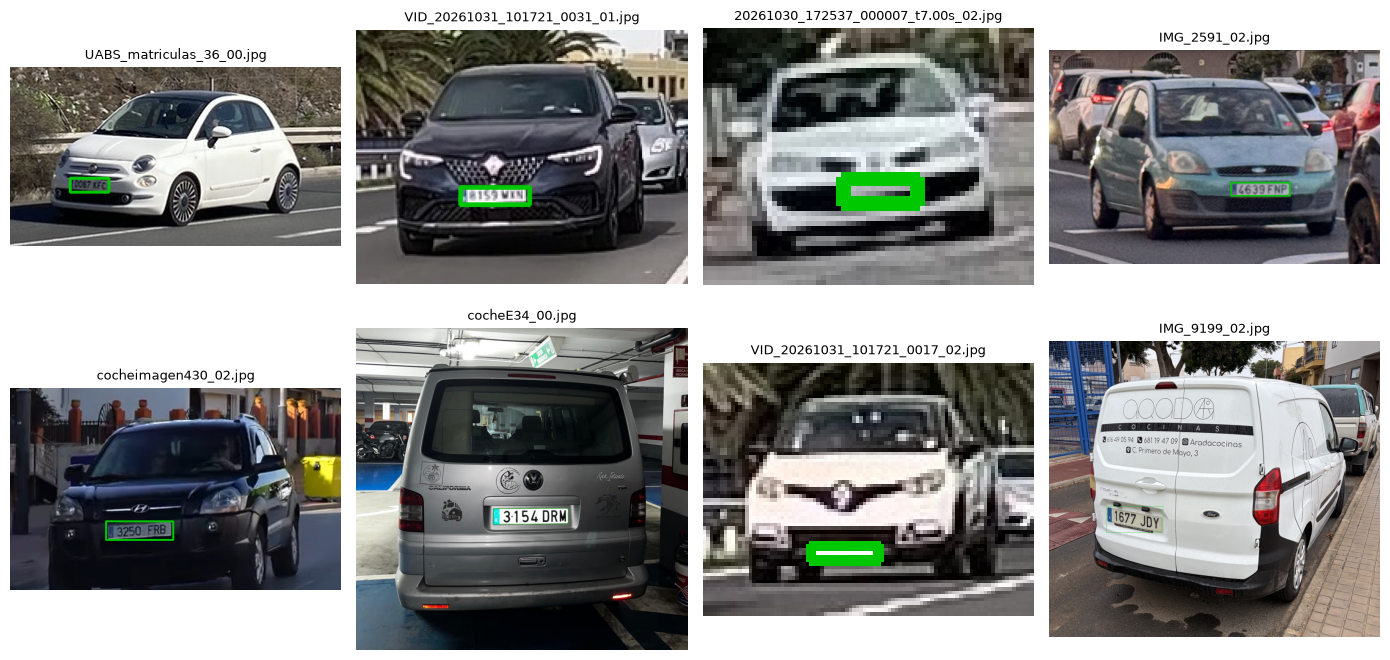

In [4]:
NAMES = sorted(p.name for p in (SPLIT / "images").iterdir())
ONE_PLATE = [name for name in NAMES if len(read_plates(name)) == 1]
EXAMPLES = random.Random(0).sample(ONE_PLATE, 8)
EXAMPLE = "matricula_ilm_43_02.jpg"

detector = ContourPlateDetector()
bgr = read_image(EXAMPLE)
trace = detector.run(bgr)
crop = trace["crop"]
truth = true_boxes(EXAMPLE, bgr.shape, crop["scale"])

show_images({name: draw_boxes(read_image(name), true_boxes(name, read_image(name).shape), GREEN) for name in EXAMPLES})

## 2. Preprocesado

Cada recorte se reescala a un ancho fijo, para unificar la comparación de tamaños, y se pasa a gris con el histograma ecualizado. También se marcan los píxeles blancos usando el espacio de color HSV (saturación baja y brillo alto):

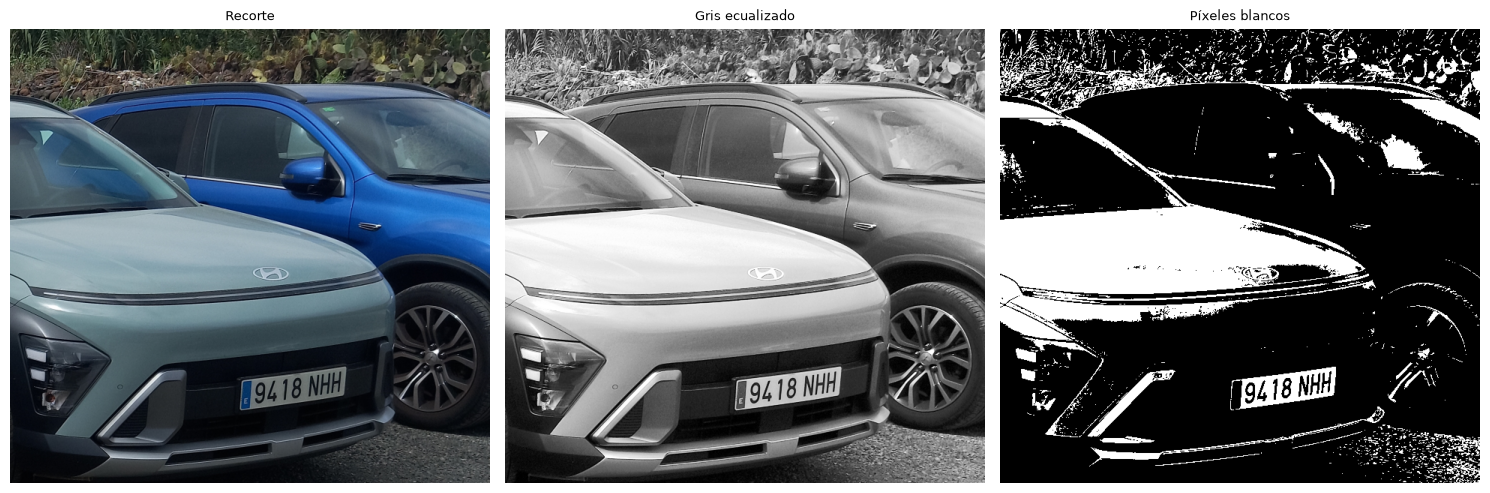

In [5]:
show_images({"Recorte": crop["bgr"], "Gris ecualizado": crop["gray"], "Píxeles blancos": crop["white"]}, cols=3, size=5)

## 3. Candidatos

Para la generación de cada candidato, se computan 3 máscaras:

- **Bordes:** Canny tras un filtro bilateral, que quita el ruido conservando los bordes, como el marco de la matrícula.
- **Zonas blancas:** apertura y cierre de los píxeles blancos, que hace que los caracteres queden como agujeros en el fondo blanco.
- **Hough:** detección de segmentos rectos cuasi horizontales o verticales. Los segmentos se alargan para formar esquinas.

Para cada contorno de las máscaras se obtiene el rectángulo de área mínima que lo engloba, que puede estar girado. Cada uno de estos rectángulos es un candidato. Su _aspect ratio_ (ancho / alto) determina su tipo: `wide` (una fila de caracteres) o `square` (dos filas), según las proporciones de las matrículas españolas. Se clasifican con un margen de 25 % para evitar fallos por distorsiones en la perspectiva.

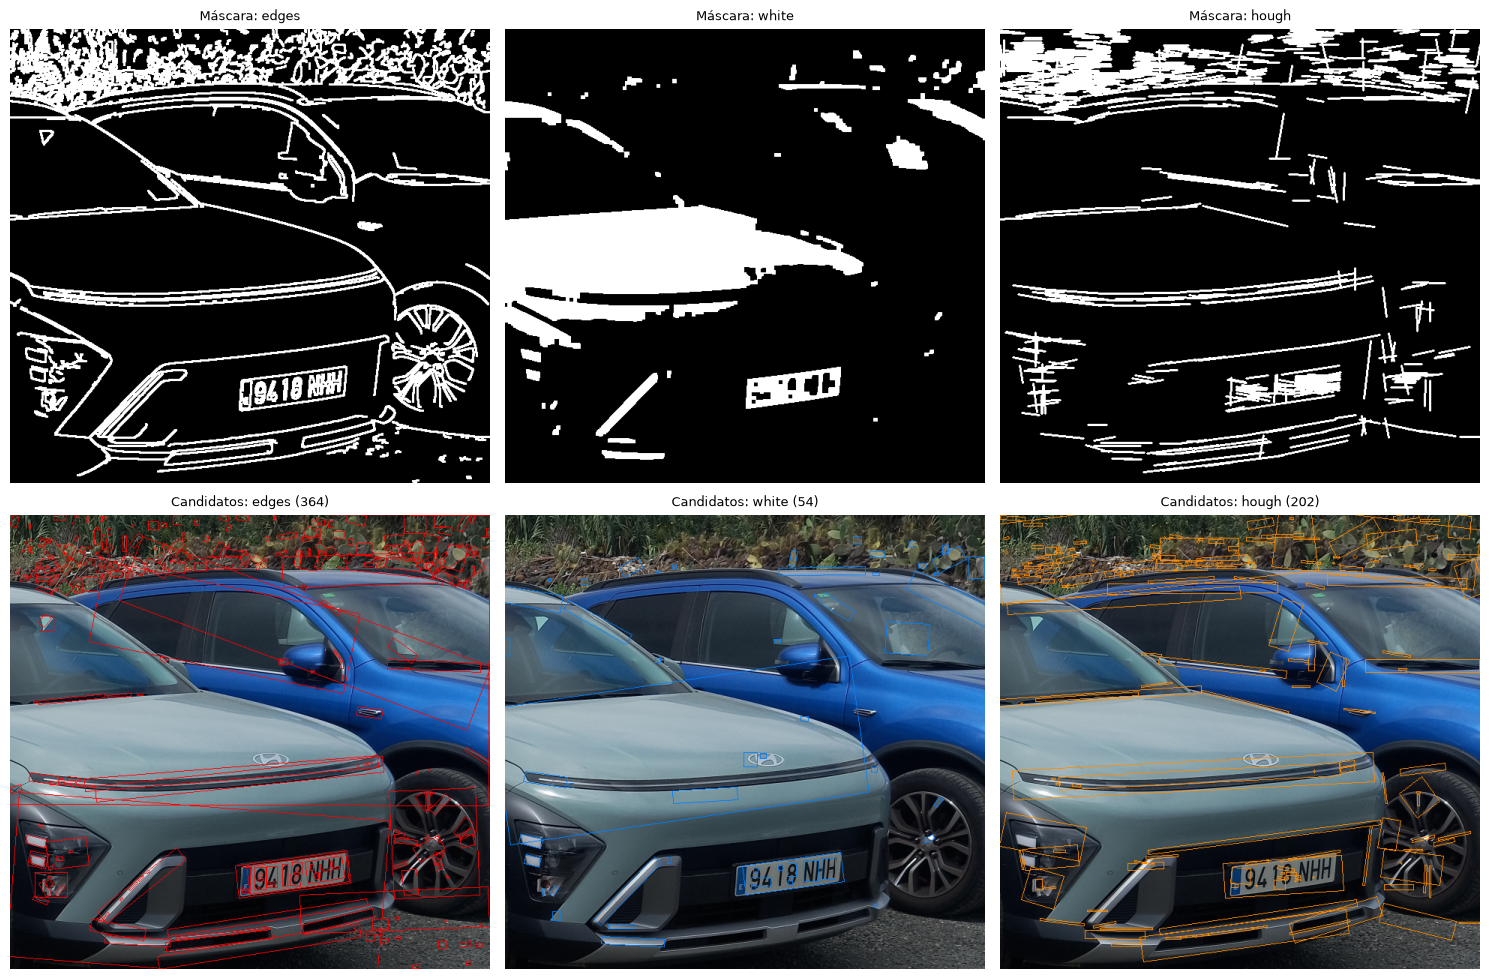

In [6]:
masks = {"edges": edge_mask(crop), "white": white_region_mask(crop), "hough": hough_line_mask(crop)}
images = {f"Máscara: {name}": mask for name, mask in masks.items()}
for name, color in SOURCE_COLORS.items():
    candidates = [c for c in trace["candidates"] if c.source == name]
    images[f"Candidatos: {name} ({len(candidates)})"] = draw_candidates(crop["bgr"], candidates, color)
show_images(images, cols=3, size=5)

## 4. Filtros

Para descartar candidatos, se usan distintos criterios:
- _Aspect ratio_ incorrecto
- Candidato detectado en el 20% superior de la imagen (solo se procesan recortes de vehículos, por lo que se presupone que la matrícula se encontrará en la parte inferior de la imagen)
- Ancho fuera del rango 5%-50% del ancho total del recorte
- Eliminar duplicados con NMS

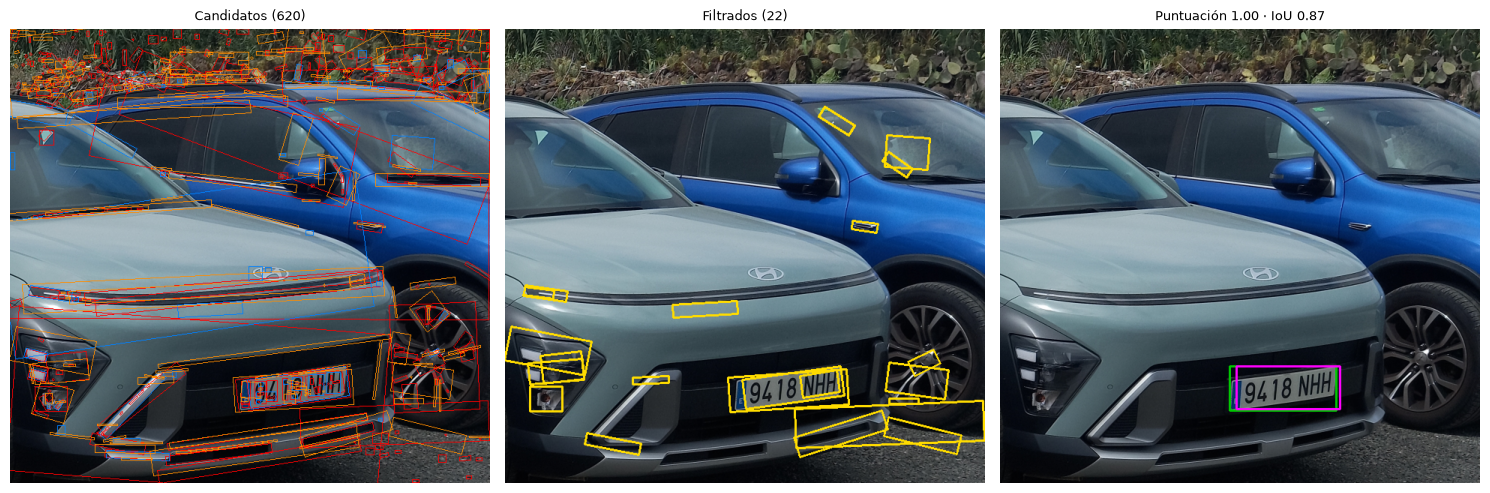

In [7]:
def stage_images(trace, truth):
    crop, best = trace["crop"], trace["best"]
    sources = crop["bgr"]
    for name, color in SOURCE_COLORS.items():
        sources = draw_candidates(sources, [c for c in trace["candidates"] if c.source == name], color)
    final = draw_boxes(crop["bgr"], truth, GREEN)
    title = "Sin candidatos"
    if best is not None:
        final = draw_boxes(final, [best.box], MAGENTA)
        title = f"Puntuación {best.score:.2f} · IoU {max((iou(best.box, t) for t in truth), default=0.0):.2f}"
    return {f"Candidatos ({len(trace['candidates'])})": sources,
            f"Filtrados ({len(trace['survivors'])})": draw_candidates(crop["bgr"], trace["survivors"], YELLOW, 2),
            title: final}


show_images(stage_images(trace, truth), cols=3, size=5)

## 5. Puntuación

Una vez filtrados los candidatos, se endereza su _bounding box_ para tener una rotación de 0º, y se reduce su tamaño en 8% por cada lado para eliminar el marco de la matrícula. Sobre este candidato procesado, se evalúan 5 criterios:

- `white`: fracción de píxeles blancos, que puntúa 1 a partir del 50 %.
- `lower half`: 1 si el centro del candidato está en la mitad inferior del recorte.
- `width`: 1 si el candidato mide al menos el 15 % del ancho del recorte. Los candidatos más estrechos suelen ser logos, letras sueltas o piezas pequeñas.
- `vertical profile`, `horizontal profile`: [perfiles de brillo](#perfiles-de-brillo) horizontales y verticales.

### Perfiles de brillo

Un perfil es la media del brillo (en escala de grises) del interior a lo largo de cada fila o de cada columna (`profile`). Como una matrícula tiene caracteres oscuros sobre fondo claro, las filas o columnas que cruzan caracteres tienen una media más baja y forman un **valle** en la curva (`find_valleys`).

- **Perfil vertical:** un valle por cada fila de caracteres. Puntúa más cuanto más coincida el número de valles y más marcados sean.
- **Perfil horizontal:** dentro de cada fila de caracteres (`character_rows`), un valle por carácter. Puntúa 1 si el número de valles está en el rango esperado (4 a 10 en una `wide`, 2 a 6 por fila en una `square`), y menos cuanto más se aleja.

Por ejemplo, para la imagen de ejemplo, estos son los perfiles calculados:

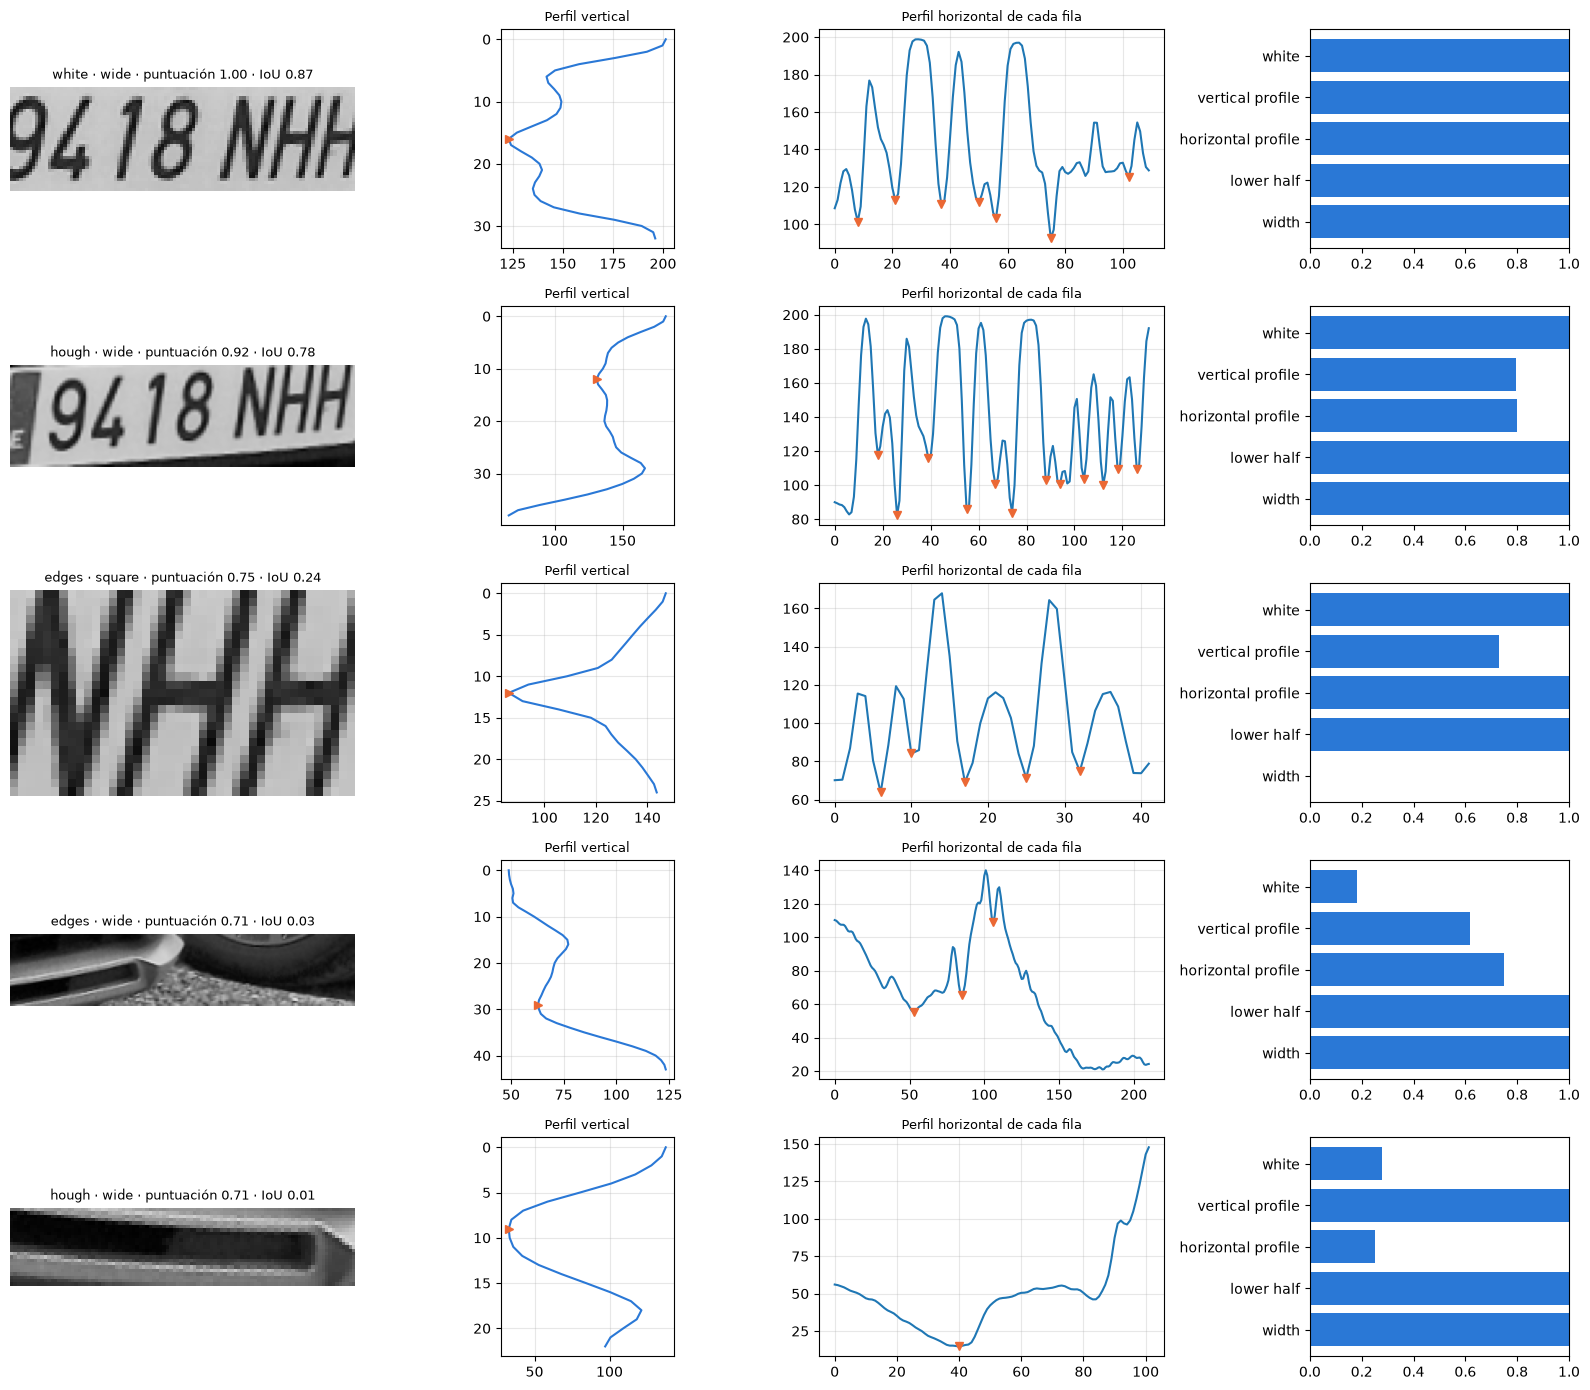

In [8]:
def plot_valleys(ax, values, vertical=False):
    valleys, _ = find_valleys(values)
    positions = np.arange(len(values))
    if vertical:
        ax.plot(values, positions, color="#2a78d6")
        ax.plot(values[valleys], valleys, ">", color="#eb6834")
        ax.invert_yaxis()
    else:
        ax.plot(positions, values)
        ax.plot(valleys, values[valleys], "v", color="#eb6834")
    ax.grid(alpha=0.3)


def show_candidate_analysis(trace, truth, n=5):
    candidates = trace["scored"][:n]
    fig, axes = plt.subplots(len(candidates), 4, figsize=(16, 2.8 * len(candidates)), squeeze=False,
                             gridspec_kw={"width_ratios": [2, 1, 2, 1.5]})
    for row, c in zip(axes, candidates):
        gray = candidate_interior(c, trace["crop"])["gray"]
        best_iou = max((iou(c.box, t) for t in truth), default=0.0)
        row[0].imshow(gray, cmap="gray", vmin=0, vmax=255)
        row[0].set_title(f"{c.source} · {c.kind} · puntuación {c.score:.2f} · IoU {best_iou:.2f}", fontsize=9)
        row[0].axis("off")
        plot_valleys(row[1], profile(gray, 1), vertical=True)
        row[1].set_title("Perfil vertical", fontsize=9)
        for top, bottom in character_rows(gray, c.kind):
            plot_valleys(row[2], profile(gray[top:bottom], 0))
        row[2].set_title("Perfil horizontal de cada fila", fontsize=9)
        row[3].barh(list(c.features), list(c.features.values()), color="#2a78d6")
        row[3].set_xlim(0, 1)
        row[3].invert_yaxis()
    plt.tight_layout()
    plt.show()


show_candidate_analysis(trace, truth)

## 6. Ejemplos

Detección final en los recortes de ejemplo:

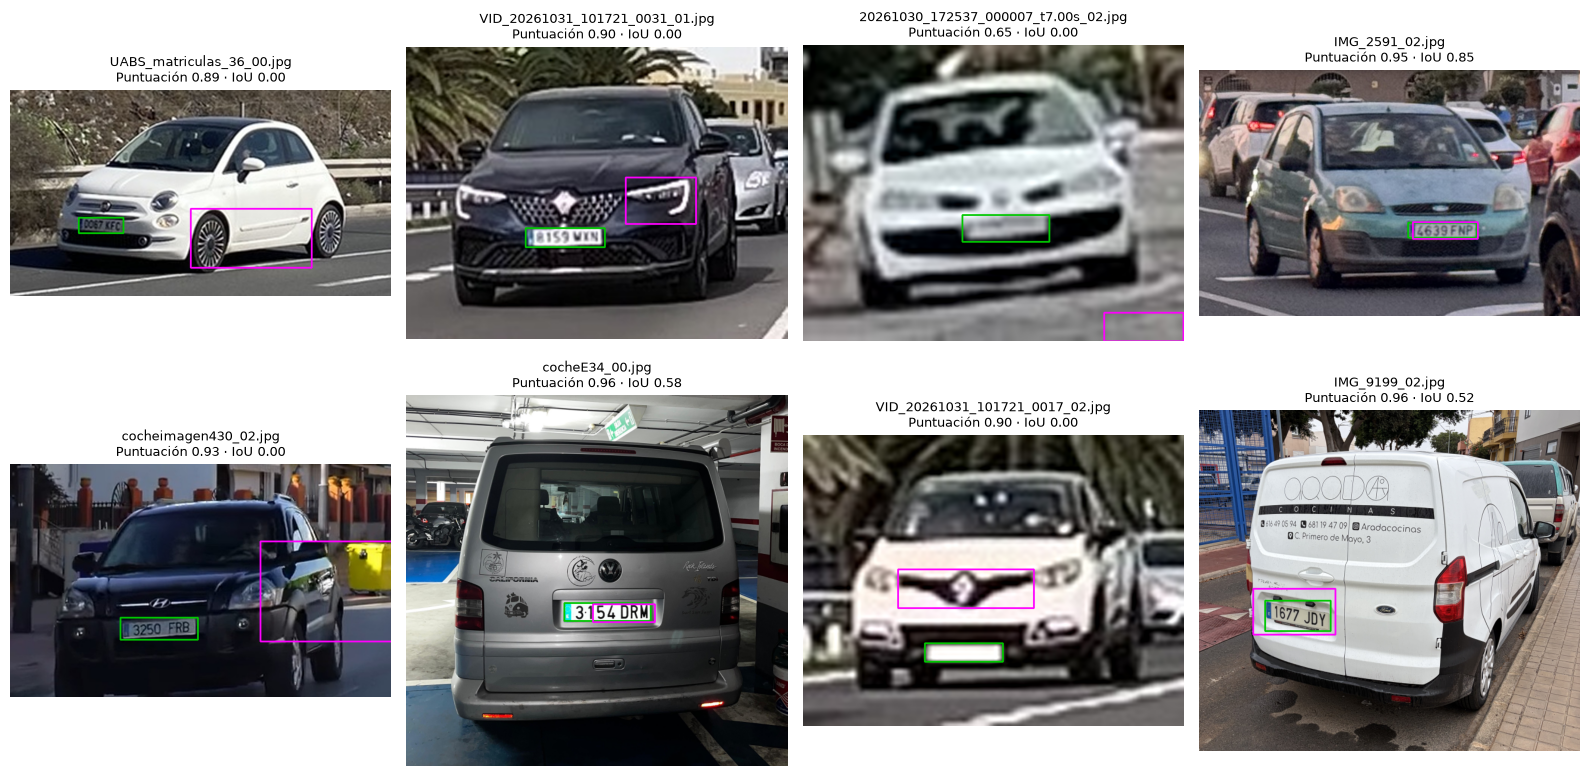

In [9]:
finals = {}
for name in EXAMPLES:
    example = read_image(name)
    example_trace = detector.run(example)
    title, img = list(stage_images(example_trace, true_boxes(name, example.shape, example_trace["crop"]["scale"])).items())[-1]
    finals[f"{name}\n{title}"] = img
show_images(finals, cols=4, size=4)